# Start

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
data = 'credit_risk_scoring_data.csv'


In [3]:
df = pd.read_csv(data)
df.head()


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


# Data Preparation and Cleaning

1. make columns name lowercase
2. Re-encoding the categorical variables - 
    The columns "status", "home", "marital", "records" and "job" are categorical, but in the file they are encoded as numbers. For example, status is 1, 2 or 0. That's not very intuitive, so we decode them into strings.
3. Replace the missing numerical variables with NaN
4. Removing the one unknown status


In [4]:
# 1. make columns name lowercase
df.columns = df.columns.str.lower()

In [5]:
# 2. Re-encoding the categorical variables
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [6]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [7]:
#3. Replace the missing numerical variables with NaN
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [8]:
#4. Removing the unknown status
df[df.status == 'unk']

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
3309,unk,10,private,60,25,single,no,fixed,35,148.0,3000.0,0.0,1500,1888


In [9]:
df = df[df.status != 'unk'].reset_index(drop=True)

# Dataset train/validation/test split

1. split the dataset into df_full_train 80% + df_test 20% , then df_train 60% + df_val 20%
2. prepare target variable - encode status: 0 for ok, 1 for default.


In [10]:
#1. split the dataset into df_full_train 80% + df_test 20% , then df_train 60% + df_val 20%
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
#2. prepare target variable - encode status: 0 for ok, 1 for default.

y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [13]:
del df_train['status']
del df_val['status']
del df_test['status']

# Decision tree

## train the decision tree

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [15]:
train_dicts = df_train.fillna(0).to_dict(orient='records')
val_dicts = df_val.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [16]:
dt = DecisionTreeClassifier(max_depth=5)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [17]:
y_pred_train = dt.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, y_pred_train)
print('train:', auc_train)

y_pred_val = dt.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_val)
print('val:', auc_val)

train: 0.8433781899611289
val: 0.7669377103969388


In [18]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- assets <= 4250.00
|   |   |   |   |--- income <= 20.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  20.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- assets >  4250.00
|   |   |   |   |--- debt <= 1850.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- debt >  1850.00
|   |   |   |   |   |--- class: 1
|   |   |--- income >  74.50
|   |   |   |--- seniority <= 5.50
|   |   |   |   |--- amount <= 1330.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- amount >  1330.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- seniority >  5.50
|   |   |   |   |--- income <= 114.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- income >  114.50
|   |   |   |   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- assets <= 8750.00
|   |   |   |--- time <= 27.00
|   |   |   |   |--- home=rent <= 0.50
|   |   |   |   |   |--- class: 0
|   |   | 

## Find the best max_depth 
-- by plotting the train and validation AUC scores for depths from 1 to 10.

In [19]:
scores = []

for depth in range(1, 21):
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)

    y_pred_train = dt.predict_proba(X_train)[:, 1]
    y_pred_val = dt.predict_proba(X_val)[:, 1]

    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)

    scores.append((depth, auc_train, auc_val))

In [20]:
for depth, auc_train, auc_val in scores:
    print(
        f'depth: {depth:2d} | '
        f'train: {auc_train:.4f} | '
        f'val: {auc_val:.4f} | '
        f'gap: {((auc_train - auc_val)*100):.4f}'
    )

    best = max(scores, key=lambda x: x[2])

print()
print('Best depth:', best[0])
print('Best train AUC:', best[1])
print('Best validation AUC:', best[2])

depth:  1 | train: 0.6283 | val: 0.6059 | gap: 2.2402
depth:  2 | train: 0.7055 | val: 0.6685 | gap: 3.6973
depth:  3 | train: 0.7761 | val: 0.7389 | gap: 3.7194
depth:  4 | train: 0.8164 | val: 0.7613 | gap: 5.5147
depth:  5 | train: 0.8434 | val: 0.7669 | gap: 7.6440
depth:  6 | train: 0.8745 | val: 0.7499 | gap: 12.4667
depth:  7 | train: 0.9000 | val: 0.7343 | gap: 16.5713
depth:  8 | train: 0.9246 | val: 0.7271 | gap: 19.7527
depth:  9 | train: 0.9476 | val: 0.7074 | gap: 24.0181
depth: 10 | train: 0.9633 | val: 0.6905 | gap: 27.2758
depth: 11 | train: 0.9788 | val: 0.6862 | gap: 29.2613
depth: 12 | train: 0.9876 | val: 0.6785 | gap: 30.9119
depth: 13 | train: 0.9933 | val: 0.6789 | gap: 31.4462
depth: 14 | train: 0.9965 | val: 0.6581 | gap: 33.8415
depth: 15 | train: 0.9985 | val: 0.6591 | gap: 33.9442
depth: 16 | train: 0.9996 | val: 0.6564 | gap: 34.3235
depth: 17 | train: 0.9999 | val: 0.6513 | gap: 34.8666
depth: 18 | train: 1.0000 | val: 0.6371 | gap: 36.2906
depth: 19 | tra

In [21]:
import matplotlib.pyplot as plt

depths = [x[0] for x in scores]
train_auc = [x[1] for x in scores]
val_auc = [x[2] for x in scores]

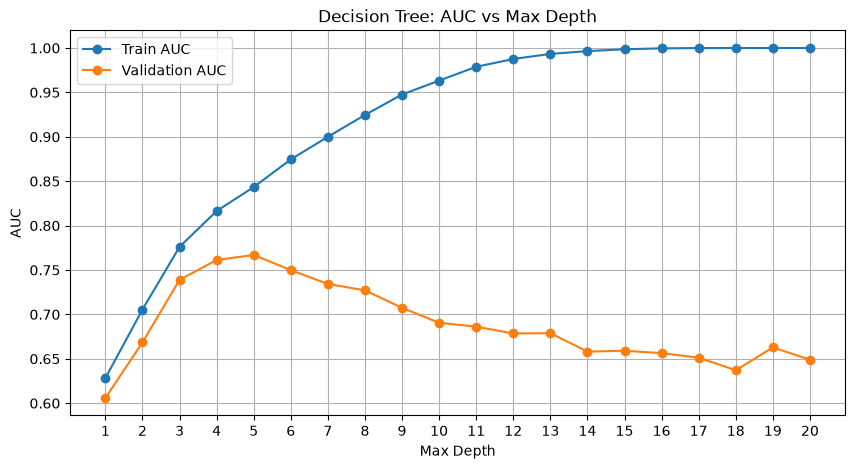

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(depths, train_auc, label='Train AUC', marker='o')
plt.plot(depths, val_auc, label='Validation AUC', marker='o')

plt.xlabel('Max Depth')
plt.ylabel('AUC')
plt.title('Decision Tree: AUC vs Max Depth')

plt.xticks(depths)
plt.legend()
plt.grid()

plt.show()

## Investigate the most important features

In [23]:
importance = pd.Series(
    dt.feature_importances_,
    index=dv.get_feature_names_out()
)

importance.sort_values(ascending=False)

income               0.173358
price                0.104403
age                  0.099268
amount               0.097607
assets               0.094239
seniority            0.093794
records=no           0.090909
job=partime          0.064371
expenses             0.050782
time                 0.032713
home=rent            0.019158
debt                 0.018993
job=fixed            0.009520
marital=separated    0.007519
home=other           0.007244
home=parents         0.007124
home=owner           0.005676
marital=single       0.005050
marital=divorced     0.003492
job=others           0.003367
job=freelance        0.002927
marital=married      0.002897
home=private         0.002835
marital=widow        0.001386
home=ignore          0.001368
home=unk             0.000000
job=unk              0.000000
marital=unk          0.000000
records=yes          0.000000
dtype: float64

In [24]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    dt,
    X_val,
    y_val,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=dv.get_feature_names_out()
)

importance.sort_values(ascending=False)

records=no           0.034285
job=partime          0.031837
assets               0.027792
amount               0.023435
income               0.018597
price                0.011837
home=rent            0.009275
time                 0.009130
seniority            0.003358
marital=married      0.003342
home=private         0.002605
job=others           0.002507
home=parents         0.002021
home=owner           0.000552
marital=widow        0.000000
marital=unk          0.000000
job=unk              0.000000
home=ignore          0.000000
home=unk             0.000000
records=yes          0.000000
job=freelance       -0.000080
marital=separated   -0.000531
marital=single      -0.000747
marital=divorced    -0.000889
home=other          -0.001852
age                 -0.003788
debt                -0.004285
expenses            -0.005002
job=fixed           -0.005393
dtype: float64

## Model Tuning

1. select max-depth
2. add min_samples_leaf

In [25]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.767
   6 -> 0.751
  10 -> 0.681
  15 -> 0.659
  20 -> 0.647
None -> 0.649


In [26]:
scores = []

for depth in [3,4, 5, 6, 7]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

In [27]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                            
max_depth             3      4      5      6      7
min_samples_leaf                                   
1                 0.739  0.761  0.766  0.750  0.740
5                 0.739  0.761  0.768  0.759  0.758
10                0.739  0.761  0.762  0.778  0.763
15                0.738  0.764  0.773  0.785  0.779
20                0.736  0.761  0.774  0.774  0.779
100               0.736  0.756  0.763  0.776  0.780
200               0.729  0.747  0.759  0.768  0.768
500               0.680  0.680  0.680  0.680  0.680

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

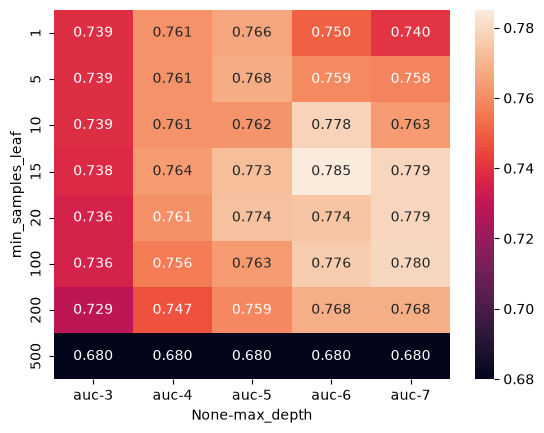

In [28]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")


## Tuning min_samples_leaf


In [30]:

from sklearn.ensemble import RandomForestClassifier

scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

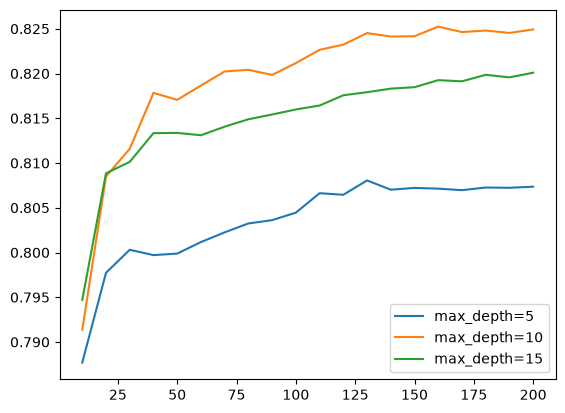

In [ ]:


columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

In [37]:
max_depth = 10


In [ ]:

scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

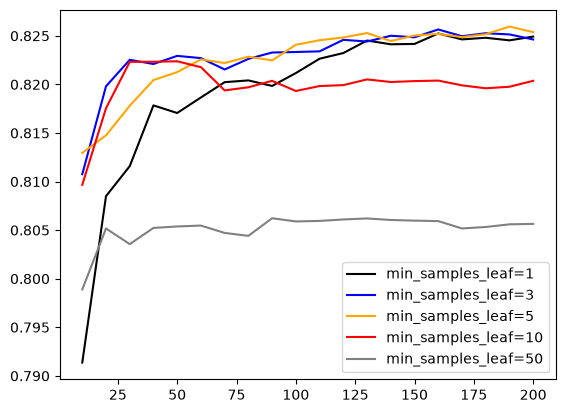

In [34]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

In [38]:
min_samples_leaf = 3

In [39]:
# yields the final model with the best hyperparameters

rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: